# 第 8 课 · BLP 随机系数需求估计

不同商圈的门店销售五件商品。门店记录每件商品的特征、价格和销量，还能估计没有在店内购买的顾客比例。两件商品的替代关系会怎样随它们的特征和商圈的产品构成而变？店家又可能根据研究者看不到的畅销程度定价，如何利用外生变化估计价格系数与偏好异质性？

**建议配合第 9–11 周学习，配套自学约 10–14 小时。** 依次学习给定类型的份额与积分、内层份额反演，以及外层 GMM 与局部识别。需要[第 6 课](06-aggregate-logit-iv-gmm.ipynb)的 IV/GMM 和[第 7 课](07-nested-logit.ipynb)的份额反演。实验估计一个随机系数的需求模型。价格由模拟中的简化规则生成。估计对象是需求参数。

## 1. 从个体选择到市场份额

记 $t$ 为市场，$j$ 为产品，$i$ 为消费者。每位消费者至多买一件商品，也可以选择外部选项。以 8 元作为价格的中心值，设效用为

$$
\begin{aligned}
 u_{ijt} &= \delta_{jt}+\sigma x_{jt}\nu_i+\varepsilon_{ijt},\\
 \delta_{jt} &= \beta_0+\beta_x x_{jt}+\beta_p(p_{jt}-8)+\xi_{jt},\\
 u_{i0t}&=\varepsilon_{i0t}.
\end{aligned}
$$

$x_{jt}$ 是已中心化的商品特征，例如携带便利度。$\xi_{jt}$ 是研究者看不到的产品吸引力。$\nu_i\sim N(0,1)$ 是消费者的偏好，独立于市场产品数据，$\varepsilon_{ijt}$ 是与其独立的标准 Gumbel 冲击，同时在选项与消费者间相互独立。$\beta_x$ 是平均特征系数，$\sigma\ge0$ 是该系数的人群标准差。因为标准正态分布对称，改变 $\sigma$ 的符号不会改变市场份额，所以约定取非负值。价格系数 $\beta_p$ 对消费者相同。模型中的负价格效应由 $\beta_p<0$ 表示。

给定 $\nu$，概率满足个体层面的 Logit。以 $\nu_r,w_r$ 表示标准正态积分的节点与权重。市场份额是这些条件概率的加权平均。

$$
P_{rjt}=\frac{\exp(\delta_{jt}+\sigma x_{jt}\nu_r)}{1+\sum_k\exp(\delta_{kt}+\sigma x_{kt}\nu_r)},
\qquad
s_{jt}(\delta,\sigma)\approx\sum_rw_rP_{rjt},\qquad \sum_rw_r=1.
$$

条件于同一个偏好时，相对选择概率仍有 Logit 的 IIA 性质。对偏好积分后，提价对不同偏好消费者的影响大小不同，整体替代模式可以随特征而变。$\sigma=0$ 时退化为齐次 Logit 市场份额。这里的 $\sigma$ 是特征系数的标准差，与第 7 课的组内相关参数是两个模型参数。

本课采用确定性的 Gauss–Hermite 数值积分。每次评价目标函数用同一组节点，使份额和矩条件的变化来自试算参数。换用模拟积分时，也要在不同试算参数之间共用随机抽样。

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize_scalar

# Jupyter 可能从课程根目录或 lessons 目录启动内核。
repo = Path.cwd()
if not (repo / "src" / "blp_demand.py").is_file():
    repo = repo.parent
if not (repo / "src" / "blp_demand.py").is_file():
    raise FileNotFoundError("请保留课程目录结构，并从仓库根目录或 lessons 目录运行。")
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from src.blp_demand import invert_shares, market_probabilities, normal_quadrature

estimate_nodes, estimate_weights = normal_quadrature(21)
assert np.isclose(estimate_weights.sum(), 1)
assert np.isclose(estimate_weights @ estimate_nodes, 0)
assert np.isclose(estimate_weights @ estimate_nodes**2, 1)

## 2. 构造市场数据和工具变量

用 220 个独立市场，每个市场 5 件产品。各地上架产品的平均特征和特征的分散程度均有变化。模拟器按下面的定价规则生成价格，单位为元/件。

$$
p_{jt}=8+0.8z_{jt}+0.45x_{jt}+0.85\xi_{jt}+\eta_{jt}.
$$

$z_{jt}$ 是模拟的成本变量，与需求冲击独立。$\eta_{jt}$ 是独立的定价噪声。同一市场产品的 $\xi_{jt}$ 有一个共同分量。因为报价随 $\xi_{jt}$ 变化，价格内生。在本实验中，市场足够大，销量份额直接取模拟模型的选择概率。份额由更密的 41 点积分生成。

估计使用 $X=[1,x,p-8]$。工具矩阵 $Z$ 包含外生解释变量 $1,x$、成本变量 $z$、本品特征平方 $x_j^2$、本品与其他产品平均特征的交互 $x_j\bar x_{-j}$，以及其他产品特征平方的平均 $\overline{x_{-j}^2}$。后面三个矩提供有关异质性的额外信息。错设 $\sigma$ 时，反演得到的 $\delta$ 可能出现和特征或组合相关的系统偏差。由于这里的特征和产品组合由模拟器独立于 $\xi$ 抽取，$E[Z'\xi]=0$ 由数据生成过程保证。用真实数据时，需要说明市场进入、产品设计和成本变化为何满足相应的外生性与排除限制。

In [2]:
rng = np.random.default_rng(8246)
market_count, product_count = 220, 5
market_location = rng.uniform(-0.8, 0.8, (market_count, 1))
market_spread = rng.uniform(0.3, 1.25, (market_count, 1))
feature = market_location + market_spread * rng.uniform(-1.5, 1.5, (market_count, product_count))
cost_shifter = rng.uniform(-1.7, 1.7, feature.shape)
demand_shock = 0.16 * rng.normal(size=(market_count, 1)) + 0.24 * rng.normal(size=feature.shape)
pricing_noise = 0.32 * rng.normal(size=feature.shape)
price = 8 + 0.8 * cost_shifter + 0.45 * feature + 0.85 * demand_shock + pricing_noise

observations = feature.size
regressors = np.column_stack((np.ones(observations), feature.ravel(), (price - 8).ravel()))
feature_sq = feature**2
rival_mean = (feature.sum(axis=1, keepdims=True) - feature) / (product_count - 1)
rival_mean_sq = (feature_sq.sum(axis=1, keepdims=True) - feature_sq) / (product_count - 1)
instruments = np.column_stack((
    regressors[:, :2], cost_shifter.ravel(), feature_sq.ravel(),
    (feature * rival_mean).ravel(), rival_mean_sq.ravel(),
))

true_beta = np.array([-0.7, 0.8, -0.8])
true_sigma = 1.15
true_delta = (regressors @ true_beta).reshape(feature.shape) + demand_shock
data_nodes, data_weights = normal_quadrature(41)
observed_shares = market_probabilities(true_delta, feature, true_sigma, data_nodes).swapaxes(-1, -2) @ data_weights
outside_shares = 1 - observed_shares.sum(axis=1)

print(f"市场数 {market_count}, 每市场产品数 {product_count}, 产品市场观测数 {observations}")
print(f"报价区间 {price.min():.2f}–{price.max():.2f} 元")
print(f"最低产品份额 {observed_shares.min():.2%}, 最低外部份额 {outside_shares.min():.2%}")
print(f"价格与不可观测需求冲击的样本相关系数 {np.corrcoef(price.ravel(), demand_shock.ravel())[0, 1]:.3f}")

市场数 220, 每市场产品数 5, 产品市场观测数 1100
报价区间 5.44–10.28 元
最低产品份额 1.63%, 最低外部份额 9.59%
价格与不可观测需求冲击的样本相关系数 0.306


这里可以打印价格与 $\xi$ 的相关系数，因为我们知道模拟器里的 $\xi$。以下估计程序的输入只有观测份额、价格、特征和工具。$\xi$ 与真实参数留作事后核对。

## 3. 内层：给定 $\sigma$，反演平均效用

对每一个试算的 $\sigma$，求 $\delta_t$ 使模型份额 $s_t(\delta_t,\sigma)$ 等于观测份额 $s_t^{\mathrm{obs}}$。BLP 更新式把低估产品份额的平均效用上调，把高估份额的平均效用下调。

$$
\delta_t^{(k+1)}=\delta_t^{(k)}+\log s_t^{\mathrm{obs}}-\log s_t(\delta_t^{(k)},\sigma).
$$

实现从齐次 Logit 的反演 $\log s_{jt}^{\mathrm{obs}}-\log s_{0t}^{\mathrm{obs}}$ 起步。内外份额均须严格大于零。逐市场计算对数份额并迭代，直到所有产品的最大绝对对数份额误差小于阈值。外部份额由 $1-\sum_js_{jt}$ 自动确定。真实数据若有零销量或外部份额口径不一致，应先调查市场定义和销量数据，再选适当的估计方法。该实现对非正份额报错。

**推导练习。** 在一个市场内令 $T(\delta)=\delta+\log s^{\mathrm{obs}}-\log s(\delta,\sigma)$。利用条件 Logit 的导数可得

$$
\frac{\partial T_j}{\partial\delta_k}=\frac{\sum_r w_rP_{rj}P_{rk}}{s_j(\delta,\sigma)}.
$$

每行元素非负，行和是 $1-P_{r0}$ 按 $w_rP_{rj}$ 加权的平均，小于 1。外部选项有正概率时，该式解释了局部的误差收缩。在一个凸闭集内，如果更新映射将该集合映入自身，且行和的统一上界严格小于 1，压缩映射定理给出从集合内任一点收敛到唯一固定点。行和逐点小于 1 本身不足以给出全空间的统一收缩率。代码报告迭代和误差，用于检查实际计算。 [Berry、Levinsohn 和 Pakes（1995），附录 I](https://www.its.caltech.edu/~mshum/gradio/papers/BerryLevinsohnPakes1995.pdf)

In [3]:
logit_delta = np.log(observed_shares) - np.log(outside_shares[:, None])
for trial_sigma in (0.0, 0.75, 1.50):
    inverted, updates, log_error = invert_shares(
        observed_shares, feature, trial_sigma, estimate_nodes, estimate_weights
    )
    if trial_sigma == 0.0:
        np.testing.assert_allclose(inverted, logit_delta, atol=1e-12, rtol=0)
    print(f"sigma = {trial_sigma:.2f}: updates = {updates:3d}, max log-share error = {log_error:.2e}")

sigma = 0.00: updates =   0, max log-share error = 5.55e-16
sigma = 0.75: updates = 199, max log-share error = 9.49e-11


sigma = 1.50: updates = 220, max log-share error = 9.39e-11


每个试算值都能拟合份额，背后的平均效用不同。由百分比拟合误差判断 $\sigma$ 会遇到这个困难。外层估计需要追问这些反推出来的平均效用是否和市场特征、成本变量所提供的矩条件相容。

## 4. 外层：集中掉线性参数，估计偏好异质性

给定 $\sigma$，内层得出的 $\delta(\sigma)$ 可以作为因变量，需求残差是 $\xi(\beta,\sigma)=\delta(\sigma)-X\beta$。令 $N$ 为产品市场观测数，定义

$$
 h(\sigma)=Z'\delta(\sigma)/N,\qquad A=Z'X/N,\qquad
 g_N(\beta,\sigma)=h(\sigma)-A\beta.
$$

本实验用固定的一步 GMM 权重 $W=(Z'Z/N)^{-1}$。矩条件有效、参数可识别等条件成立时可以用这一目标估计参数。权重固定并不处理市场共同冲击引起的推断问题。用 $g_N'Wg_N$ 对 $\beta$ 求一阶条件，先求线性解，再对 $\sigma$ 优化。

$$
 \hat\beta(\sigma)=(A'WA)^{-1}A'Wh(\sigma),
 \qquad
 \hat\sigma\in\arg\min_{\sigma\ge0}Q_N(\sigma),
 \qquad
 Q_N(\sigma)=g_N(\hat\beta(\sigma),\sigma)'Wg_N(\hat\beta(\sigma),\sigma).
$$

固定 $\sigma$ 时，计算相当于在 $\delta(\sigma)$ 上做 2SLS。外层不是回归一个现成的 $\delta$。每个 $\sigma$ 都要重新反演。代码先画目标函数并找到最好的网格点，再在邻近网格内细化。网格有限且目标可能有多个极值，计算结果应结合区间和目标剖面解释。

In [4]:
moment_regressors = instruments.T @ regressors / observations
if np.linalg.matrix_rank(moment_regressors) != regressors.shape[1]:
    raise ValueError("线性系数在当前工具矩阵下未满足满秩条件")
weight = np.linalg.solve(instruments.T @ instruments / observations, np.eye(instruments.shape[1]))
weighted_regressors = moment_regressors.T @ weight
linear_projection = np.linalg.solve(weighted_regressors @ moment_regressors, weighted_regressors)


def fit_at_sigma(sigma, nodes, weights):
    delta, updates, log_error = invert_shares(observed_shares, feature, sigma, nodes, weights)
    h = instruments.T @ delta.ravel() / observations
    beta = linear_projection @ h
    moments = h - moment_regressors @ beta
    return {
        "sigma": sigma, "beta": beta, "objective": float(moments @ weight @ moments),
        "delta": delta, "moments": moments, "updates": updates, "log_error": log_error,
    }


sigma_grid = np.linspace(0, 2.0, 17)
grid_fits = [fit_at_sigma(sigma, estimate_nodes, estimate_weights) for sigma in sigma_grid]
grid_objectives = np.array([point["objective"] for point in grid_fits])
best_index = grid_objectives.argmin()
search_limits = (sigma_grid[max(best_index - 1, 0)], sigma_grid[min(best_index + 1, len(sigma_grid) - 1)])
refinement = minimize_scalar(
    lambda sigma: fit_at_sigma(sigma, estimate_nodes, estimate_weights)["objective"],
    bounds=search_limits, method="bounded", options={"xatol": 1e-5},
)
if not refinement.success:
    raise RuntimeError(refinement.message)
refined = fit_at_sigma(refinement.x, estimate_nodes, estimate_weights)
estimate = min((grid_fits[best_index], refined), key=lambda fit: fit["objective"])

print(f"{'Parameter':>11} {'True':>9} {'At sigma=0':>12} {'BLP':>9}")
for label, truth, homogeneous, fitted in zip(
    ("Intercept", "Feature", "Price", "Sigma"),
    np.r_[true_beta, true_sigma], np.r_[grid_fits[0]["beta"], 0],
    np.r_[estimate["beta"], estimate["sigma"]],
):
    print(f"{label:>11} {truth:>9.3f} {homogeneous:>12.3f} {fitted:>9.3f}")
print(f"Optimal trial objective {estimate['objective']:.3g}, max log-share error {estimate['log_error']:.2e}")

  Parameter      True   At sigma=0       BLP
  Intercept    -0.700       -0.615    -0.697
    Feature     0.800        0.638     0.788
      Price    -0.800       -0.749    -0.780
      Sigma     1.150        0.000     1.110
Optimal trial objective 8.09e-05, max log-share error 9.91e-11


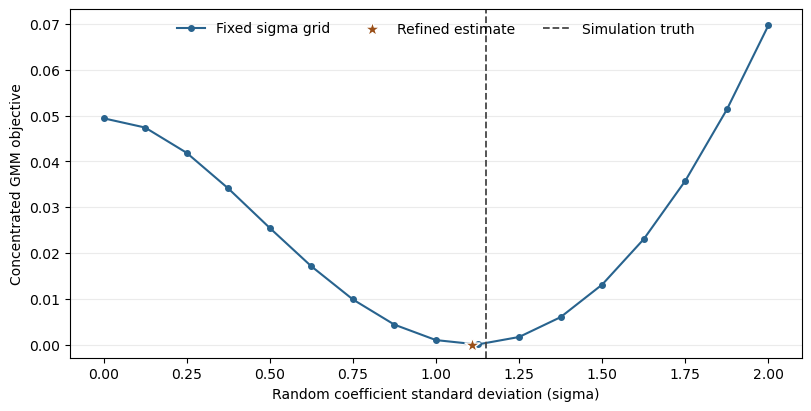

In [5]:
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.plot(sigma_grid, grid_objectives, "o-", color="#28638e", label="Fixed sigma grid", markersize=4)
ax.scatter(estimate["sigma"], estimate["objective"], marker="*", s=130, color="#9a4f18",
           edgecolor="white", zorder=3, label="Refined estimate")
ax.axvline(true_sigma, color="#474747", ls="--", lw=1.3, label="Simulation truth")
ax.set(xlabel="Random coefficient standard deviation (sigma)", ylabel="Concentrated GMM objective")
ax.set_ylim(bottom=-0.04 * grid_objectives.max())
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="upper center", frameon=False, ncol=3)
plt.show()

图的横轴是特征系数的标准差，纵轴是每次反演与集中后剩余的矩条件误差。蓝点覆盖从 0 到 2 的粗网格，星标是网格附近的细化估计，虚线是模拟真值。在默认样本中，目标函数在 $\sigma\approx1.110$ 附近达到最小，价格系数约为 −0.780。齐次 Logit 也能逐项复制观察份额，但工具矩的失配更大。这是同一模拟样本中的比较。最小目标值对应的参数可因有限样本抽样而偏离真值。

## 5. 识别诊断与数值检查

### 成本变量的第一阶段与额外矩的作用

先将价格和成本变量分别对其他工具做线性投影，再计算两组残差的相关系数。这衡量样本中的条件线性相关性。它不检验排除限制，也不诊断 $\sigma$ 是否可识别。

如果只保留 $1,x,z$，三个线性参数就能用三个矩配平。只要 $Z'X$ 满秩，每个试算 $\sigma$ 的集中目标都为零。这个实验说明，外层识别需要额外有效的限制。增加工具后，还要检查矩对参数是否有独立的响应。

In [6]:
other_instruments = instruments[:, [0, 1, 3, 4, 5]]
price_and_cost = np.column_stack(((price - 8).ravel(), cost_shifter.ravel()))
residual_prices_and_cost = price_and_cost - other_instruments @ np.linalg.lstsq(
    other_instruments, price_and_cost, rcond=None
)[0]
partial_correlation = np.corrcoef(residual_prices_and_cost.T)[0, 1]
print(f"成本变量与价格的样本条件相关系数 {partial_correlation:.3f}")

just_identified_tools = instruments[:, :3]
just_identified_matrix = just_identified_tools.T @ regressors / observations
print("只用三个矩时，三次试算得到的最大绝对样本矩")
for trial in (grid_fits[0], grid_fits[6], grid_fits[12]):
    target = just_identified_tools.T @ trial["delta"].ravel() / observations
    linear_estimate = np.linalg.solve(just_identified_matrix, target)
    residual_moments = target - just_identified_matrix @ linear_estimate
    print(f"sigma = {trial['sigma']:.2f}: {np.abs(residual_moments).max():.2e}")

成本变量与价格的样本条件相关系数 0.899
只用三个矩时，三次试算得到的最大绝对样本矩
sigma = 0.00: 0.00e+00
sigma = 0.75: 5.55e-17
sigma = 1.50: 1.11e-16


### 检查联合矩的雅可比矩阵、积分误差与反演误差

用中心差分近似 $\partial h/\partial\sigma$，再与 $-A$ 拼接，得到矩对全部四个参数的局部雅可比矩阵。查看其奇异值。列满秩说明在这个样本估计点附近，各参数引起的矩变化方向可以区分。奇异值受尺度影响，不能直接解读为统计显著性。样本点的局部判据也不能证明总体参数唯一或估计精确。若目标剖面平坦、极小值在边界或对工具集合敏感，要结合市场变化和工具构造进一步诊断。$\sigma=0$ 时还要留意对称分布使份额对 $\sigma$ 的一阶导数为零。

随后比较不同积分节点数下的固定点与目标值。反演误差是同一组节点下求解方程的误差；节点敏感性反映积分近似带来的计算差异。这两个检查都不能替代识别诊断。

In [7]:
step = 1e-4
sigma_hat = estimate["sigma"]
if sigma_hat > step:
    plus = fit_at_sigma(sigma_hat + step, estimate_nodes, estimate_weights)["delta"]
    minus = fit_at_sigma(sigma_hat - step, estimate_nodes, estimate_weights)["delta"]
    sigma_derivative = instruments.T @ ((plus - minus).ravel() / (2 * step)) / observations
    jacobian = np.column_stack((-moment_regressors, sigma_derivative))
    print("联合矩雅可比矩阵的奇异值", np.round(np.linalg.svd(jacobian, compute_uv=False), 4))
else:
    print("估计值接近边界，跳过中心差分，结合单侧目标剖面检查。")

print(f"{'Nodes':>6} {'Max |delta-delta21|':>21} {'Objective at fitted sigma':>27}")
for order in (11, 21, 41):
    other_fit = fit_at_sigma(sigma_hat, *normal_quadrature(order))
    delta_diff = np.abs(other_fit["delta"] - estimate["delta"]).max()
    print(f"{order:>6d} {delta_diff:>21.3g} {other_fit['objective']:>27.6g}")

# 用生成数据时的较密积分规则和真值单独检查反演程序。
check_delta, _, check_log_error = invert_shares(
    observed_shares, feature, true_sigma, data_nodes, data_weights
)
np.testing.assert_allclose(check_delta, true_delta, atol=3e-9, rtol=0)
print(f"真值和同一积分规则下的最大平均效用误差 {np.abs(check_delta - true_delta).max():.2e}")

fitted_shares = market_probabilities(
    estimate["delta"], feature, sigma_hat, estimate_nodes
).swapaxes(-1, -2) @ estimate_weights
print(f"估计点最大份额误差 {np.abs(fitted_shares - observed_shares).max():.2e}")

联合矩雅可比矩阵的奇异值 [1.5009 0.8951 0.6742 0.1412]
 Nodes   Max |delta-delta21|   Objective at fitted sigma
    11                0.0145                 8.06946e-05


    21                     0                 8.09036e-05


    41               0.00121                  8.0945e-05


真值和同一积分规则下的最大平均效用误差 1.08e-09
估计点最大份额误差 3.94e-11


### 估计误差与推断

本课报告点估计和数值、局部识别诊断。市场内多个产品的需求冲击可能相关。若做渐近推断，应按[第 6 课](06-aggregate-logit-iv-gmm.ipynb)的思路，把工具与残差的乘积按市场加总，再估计总矩的协方差；还需使用包含内层反演变化的联合矩雅可比矩阵。把反演得到的平均效用当作已知且固定，再直接套用单次线性回归的标准误，会漏掉随机系数与线性参数共同估计带来的不确定性。弱识别或边界情形还需要相应的推断方法。


可在满足总体矩正确、市场之间独立、估计点位于参数空间内部、局部识别充分等条件的情况下，写出市场聚类的三明治方差。令 $m_t=\sum_j Z_{jt}\hat\xi_{jt}$，用 $\bar m$ 表示这些市场矩的平均。$\hat\Omega$ 直接估计样本平均矩的方差，分母因此是 $N^2$。

$$
\hat\Omega=\frac{1}{N^2}\sum_t(m_t-\bar m)(m_t-\bar m)',\qquad
\widehat{\operatorname{Var}}(\hat\beta,\hat\sigma)
=(G'WG)^{-1}G'W\hat\Omega WG(G'WG)^{-1}.
$$

这里 $G$ 是联合矩的雅可比矩阵。以同一顺序放置列，才能从对角线读出各参数的方差。

## 综合练习

1. **推导与实现。** 推导条件 Logit 对 $\delta_k$ 的导数和更新映射的行和。把初始值改成全零，验证固定点与默认初始化一致。比较最严差值阈值 $10^{-6}$ 与 $10^{-10}$ 的迭代次数、最大份额残差及估计误差。
2. **识别诊断。** 比较三组工具。第一组是 $[1,x,z]$，第二组加 $x^2$，第三组再加入两个产品组合矩。对每组重算投影矩阵和权重，画各自的集中目标，检查雅可比秩，报告 $\hat\sigma$ 对工具的敏感性。不同工具集下的目标值没有直接可比的同一尺度，重点比较同一剖面内的曲率与最低点。
3. **坏工具与外生性。** 在模拟环境中构造 $z^{\mathrm{bad}}=z+0.6\xi$，估计时用它替换 $z$。核对该工具与价格、需求冲击的相关系数，重跑估计并解释系数变化。写出为什么相关性高并不证明一个成本变量有效。
4. **积分、有限样本与模型。** 在更密的节点上重新估计 $\sigma$，报告区间限制与迭代诊断。再替换随机种子重复模拟至少 20 次，报告价格与随机系数的估计误差分布以及边界解出现次数。每次保留给定试算值使用同一组积分节点的做法。分别解释积分误差、抽样误差和工具失效。

5. **选做：市场聚类推断。** 按上式实现联合参数的聚类标准误。再把每件商品视为独立计算一遍，解释两种标准误为什么不同。指出强识别和内点近似在哪些数据条件下可能失效。

## 阅读

- Berry、Levinsohn 和 Pakes（1995），*Automobile Prices in Market Equilibrium*。阅读需求份额、矩条件和附录 I 的反演论证，再识别原文同时估计需求与供给所使用的附加条件。 [原文](https://www.its.caltech.edu/~mshum/gradio/papers/BerryLevinsohnPakes1995.pdf)
- Conlon 和 Gortmaker（2020），*Best Practices for Differentiated Products Demand Estimation with PyBLP*。关注积分、工具、目标剖面和识别诊断。 [论文](https://doi.org/10.1111/1756-2171.12352)